# 03 – Thử nghiệm và phân tích CLV

Theo `docs/05-clv-methodology.md`. Mọi tham số (g, d, horizon, r̄, freq_cap, P33/P67, τ) đọc từ
`ml_engine/artifacts/clv_config.json` do `python -m ml_engine.src.train` sinh ra; notebook không ghi đè file này.

1. CLV kỳ vọng / tiềm năng / VaR và tương quan với `Lifetime_Value`
2. So sánh 5 biến thể công thức (+ BG/NBD từ docs/05)
3. Độ nhạy theo d
4. Vì sao CLV kỳ vọng thường lớn hơn CLV tiềm năng

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from ml_engine.src.clv import sensitivity_analysis_d
from ml_engine.src.segment import clv_tier, risk_label, score, segment
from ml_engine.src.train import ARTIFACTS_DIR, RAW

config = json.loads((ARTIFACTS_DIR / "clv_config.json").read_text(encoding="utf-8"))
bundle = joblib.load(ARTIFACTS_DIR / f"{config['version']}.joblib")
df = pd.read_csv(RAW)
X = df.drop(columns="Churned")
clean = bundle["raw_pipe"].named_steps["pre"].named_steps["clean"].transform(X)  # docs/05 mục 5: CLV tính sau clean
out = score(df, bundle, config)
p = out["p_churn"].to_numpy()
print(f"{len(df):,} khách | p_churn TB {p.mean():.4f} | r̄ = {config['r_bar']} | τ = {config['tau']:.4f}")
{k: config[k] for k in ("g", "d", "horizon", "freq_cap", "P33", "P67")}

D:\WORK\Education\HK07\ML_Project\machine_learning_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


50,000 khách | p_churn TB 0.2954 | r̄ = 0.7046 | τ = 0.1857


{'g': 0.33,
 'd': 0.1,
 'horizon': 3,
 'freq_cap': 40.0,
 'P33': 141.83,
 'P67': 333.53}

> p_churn của ~70% khách (tập train) là dự đoán trên dữ liệu model đã thấy nên hơi lạc quan. Batch score thực tế cũng chấm
> như vậy; với mục đích xếp hạng và chia phân khúc, sai lệch này không đổi kết luận.

## 1. Ba chỉ số CLV

In [2]:
stats = out[["clv_pred", "clv_potential", "value_at_risk"]].describe().T
print(stats[["mean", "50%", "max"]].round(2))
for col in ("clv_potential", "clv_pred"):
    print(f"Spearman {col} với Lifetime_Value: {spearmanr(out[col], df['Lifetime_Value'])[0]:.3f}")
print(f"Tổng CLV kỳ vọng {out.clv_pred.sum() / 1e6:.1f} triệu USD | tổng VaR {out.value_at_risk.sum() / 1e6:.1f} triệu USD")

                 mean     50%      max
clv_pred       435.70  233.32  6979.56
clv_potential  352.51  215.08  4136.49
value_at_risk  100.51   24.06  4073.03
Spearman clv_potential với Lifetime_Value: 0.614
Spearman clv_pred với Lifetime_Value: 0.392
Tổng CLV kỳ vọng 21.8 triệu USD | tổng VaR 5.0 triệu USD


Tiêu chí nghiệm thu: Spearman CLV tiềm năng với `Lifetime_Value` ≥ 0,5. `Lifetime_Value` là chi tiêu **quá khứ**,
CLV là giá trị **tương lai**, nên chỉ cần cùng chiều xếp hạng chứ không cần trùng.

## 2. So sánh biến thể công thức

In [3]:
d, g, H, r_bar, tau = config["d"], config["g"], config["horizon"], config["r_bar"], config["tau"]
r = 1 - p
freq = (clean.Total_Purchases / clean.Membership_Years.clip(lower=0.5)).clip(upper=config["freq_cap"])
m_gross = clean.Average_Order_Value * freq * g
m_net = m_gross * (1 - clean.Returns_Rate / 100)


def mult(rr, horizon):
    """Hệ số nhân chiết khấu: vô hạn m·r/(1+d−r), hữu hạn Σ r^t/(1+d)^t."""
    rr = np.asarray(rr, dtype=float)
    if horizon is None:
        return rr / (1 + d - rr)
    t = np.arange(1, horizon + 1)
    return (rr[..., None] ** t / (1 + d) ** t).sum(-1)


variants = {
    "A1. Vô hạn, kỳ vọng": m_gross * mult(r, None),
    "A2. Vô hạn, tiềm năng": m_gross * mult(r_bar, None),
    "B1. 3 năm, kỳ vọng": m_gross * mult(r, H),
    "B2. 3 năm, tiềm năng": m_gross * mult(r_bar, H),
    "C. 3 năm, tiềm năng, doanh thu ròng (chọn)": m_net * mult(r_bar, H),
}
assert np.allclose(variants["C. 3 năm, tiềm năng, doanh thu ròng (chọn)"], out.clv_potential, atol=0.01)


def summarize(v):
    p33, p67 = v.quantile([0.3333, 0.6667])
    tier = clv_tier(v, p33, p67)
    seg = segment(risk_label(p, tau), tier)
    var = p * v
    return {"Trung bình (USD)": v.mean(), "Trung vị (USD)": v.median(),
            "Spearman với LTV": spearmanr(v, df["Lifetime_Value"])[0],
            "Khách S1": int((seg == "S1").sum()), "VaR S1 + S2": var[np.isin(seg, ["S1", "S2"])].sum() / var.sum(),
            "tier": tier}


summary = {k: summarize(v) for k, v in variants.items()}
table = pd.DataFrame(summary).T.drop(columns="tier")
swap = (summary["B2. 3 năm, tiềm năng"]["tier"] != summary["C. 3 năm, tiềm năng, doanh thu ròng (chọn)"]["tier"]).mean()
print(f"Trừ hàng trả lại (B2 → C) làm {swap:.1%} khách đổi tier")
table.style.format({"Trung bình (USD)": "{:,.0f}", "Trung vị (USD)": "{:,.0f}", "Spearman với LTV": "{:.3f}",
                    "Khách S1": "{:,}", "VaR S1 + S2": "{:.1%}"})

Trừ hàng trả lại (B2 → C) làm 3.0% khách đổi tier


,Trung bình (USD),Trung vị (USD),Spearman với LTV,Khách S1,VaR S1 + S2
"A1. Vô hạn, kỳ vọng","1,219",607,0.368,431,13.6%
"A2. Vô hạn, tiềm năng",516,313,0.614,"5,348",78.8%
"B1. 3 năm, kỳ vọng",470,250,0.393,"1,114",27.0%
"B2. 3 năm, tiềm năng",380,231,0.614,"5,348",78.8%
"C. 3 năm, tiềm năng, doanh thu ròng (chọn)",353,215,0.614,"5,330",78.7%


- Biến thể **kỳ vọng** (A1, B1) đã chứa sẵn p_churn nên khách rủi ro cao rơi hết xuống tier Low → ô S1 gần như trống.
  Vì vậy chia tier bằng biến thể **tiềm năng**.
- Horizon vô hạn (A2) và 3 năm (B2) **xếp hạng như nhau**, chỉ khác mức USD; chọn 3 năm để tránh giả định khách ở lại > 10 năm.
- **D. BG/NBD + Gamma-Gamma không chạy lại ở đây**: mô hình này chỉ dùng recency/frequency/tuổi khách, không phụ thuộc model churn,
  nên kết quả trong docs/05 vẫn giữ nguyên (Spearman 0,98 với B2, nhưng P(alive) chỉ đạt AUC 0,61 với nhãn Churned).

## 3. Độ nhạy theo lãi suất chiết khấu d

In [4]:
sens = sensitivity_analysis_d(clean, p, d_values=(0.08, 0.10, 0.12), freq_cap=config["freq_cap"])
base = sens.set_index("d").loc[0.10, "mean_clv_potential"]
sens["Đổi mức CLV so với d = 10%"] = (sens["mean_clv_potential"] / base - 1).map("{:+.1%}".format)
sens[["d", "mean_clv_potential", "mean_clv_expected", "P33", "P67", "Đổi mức CLV so với d = 10%",
      "spearman_vs_base_potential", "tier_swap_count"]]

,d,mean_clv_potential,mean_clv_expected,P33,P67,Đổi mức CLV so với d = 10%,spearman_vs_base_potential,tier_swap_count
0,0.08,363.83,450.98,146.37,344.22,+3.2%,1.0,0
1,0.10,352.54,435.70,141.83,333.53,+0.0%,1.0,0
2,0.12,341.86,421.29,137.54,323.43,-3.0%,1.0,1


**Đọc đúng kết quả này:** CLV tiềm năng = m × hằng số (hằng số chỉ phụ thuộc d, r̄, horizon), nên đổi d **chắc chắn**
không đổi thứ hạng (Spearman = 1; 0–1 khách đổi tier chỉ do làm tròn 2 chữ số đúng tại ranh giới P33/P67) — đây là tính chất toán học của công thức, không phải phát hiện thực nghiệm.
Điều d thực sự thay đổi là **mức USD** (khoảng ±3% khi d dao động 8–12%), ảnh hưởng tới ROI chiến dịch chứ không ảnh hưởng phân khúc.

## 4. Vì sao CLV kỳ vọng thường lớn hơn CLV tiềm năng

69.4% khách có CLV kỳ vọng > CLV tiềm năng


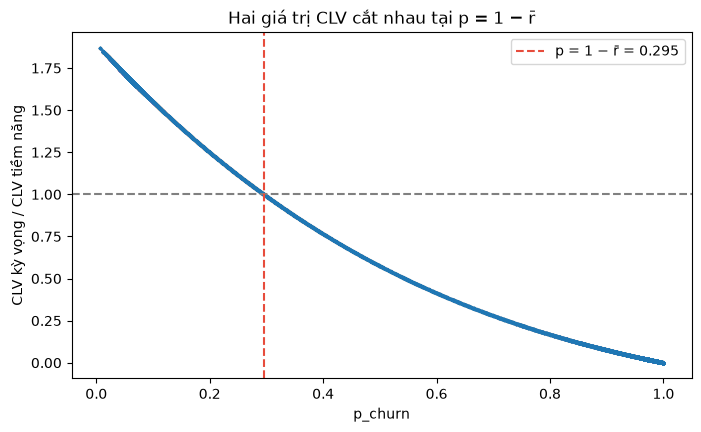

In [5]:
ok = out.clv_potential > 0
ratio = out.loc[ok, "clv_pred"] / out.loc[ok, "clv_potential"]
print(f"{(ratio > 1).mean():.1%} khách có CLV kỳ vọng > CLV tiềm năng")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(p[ok], ratio, s=2, alpha=0.3)
ax.axhline(1, color="gray", ls="--")
ax.axvline(1 - r_bar, color="#e74c3c", ls="--", label=f"p = 1 − r̄ = {1 - r_bar:.3f}")
ax.set(xlabel="p_churn", ylabel="CLV kỳ vọng / CLV tiềm năng", title="Hai giá trị CLV cắt nhau tại p = 1 − r̄")
ax.legend()
plt.show()

CLV tiềm năng dùng **r̄ chung** cho mọi khách, CLV kỳ vọng dùng **r_i = 1 − p_i riêng**. Khách có p_churn < 1 − r̄
(phần lớn tệp, vì phân phối p lệch về 0) có r_i > r̄ nên CLV kỳ vọng cao hơn. Tên "tiềm năng" nghĩa là **giá trị nếu khách hành xử
như khách trung bình** — dùng để chia tier độc lập với trục rủi ro — chứ không phải "giá trị tối đa". Cần ghi rõ điều này trong báo cáo
và tooltip trên giao diện.